# Shark-Tuna Model

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# A state is just a pair of numbers: how many sharks, how many tuna.
S = 2
T = 3

print('sharks S =', S)
print('tuna   T =', T)


sharks S = 2
tuna   T = 3


# Tuna, with no sharks
Say each tuna has `b` babies per year. Multiply by how many tuna there are:

$$T' = bT$$

Assumptions hidden in that one line:

- Every tuna can reproduce.
- Every tuna is the same.
- **Tuna only die by being eaten.** No old age, no disease.

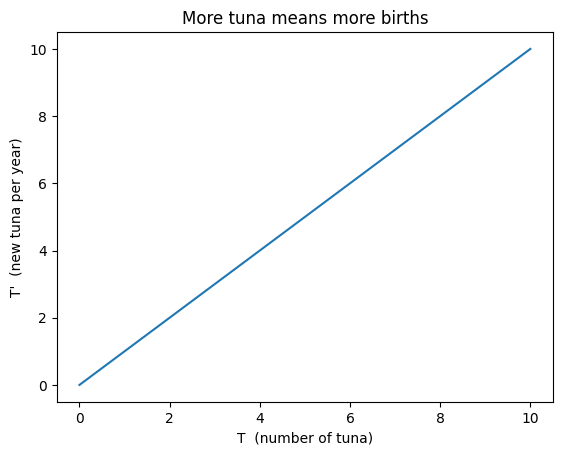

In [3]:
b = 1.0                      # tuna birth rate per tuna, per year
T = np.linspace(0, 10, 100)  # a range of tuna population sizes

plt.plot(T, b * T)
plt.xlabel('T  (number of tuna)')
plt.ylabel("T'  (new tuna per year)")
plt.title('More tuna means more births')
plt.show()


# Sharks, with no tuna

With no food:

- Sharks die at rate `d`.
- Sharks have **no** babies. In this model, eating is the only way to reproduce.

$$S' = -dS$$

The minus sign means it is an outflow. No food, so the population only shrinks.


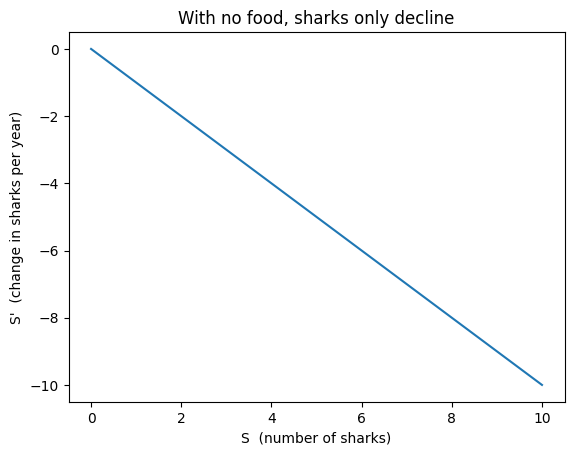

In [4]:
d = 1.0                      # shark death rate per shark, per year
S = np.linspace(0, 10, 100)

plt.plot(S, -d * S)
plt.xlabel('S  (number of sharks)')
plt.ylabel("S'  (change in sharks per year)")
plt.title('With no food, sharks only decline')
plt.show()


# Both together

Sharks and tuna only interact when they **meet**. The chance of a meeting goes up
with both populations, so it depends on `S x T`.

Let `beta` be the chance a meeting kills the tuna, and `m` be the sharks produced
per tuna eaten.

$$S' = m\beta S T - dS$$

$$T' = bT - \beta S T$$

These are the **Lotka-Volterra equations**. I set every parameter to 1.


In [5]:
b = 1.0       # tuna birth rate
d = 1.0       # shark death rate
beta = 1.0    # chance a meeting kills the tuna
m = 1.0       # sharks produced per tuna eaten

def change(S, T):
    dS = m * beta * S * T - d * S     # sharks: born from eating, minus deaths
    dT = b * T - beta * S * T         # tuna:   births, minus being eaten
    return dS, dT

print(change(2, 3))


(4.0, -3.0)


# The oscillation

The equations give me the **change**, not the populations themselves. There is no
formula for the curves, so I step through time instead:

```
new value = old value + dt * rate
```

Do that thousands of times with a small `dt` and the curves appear.


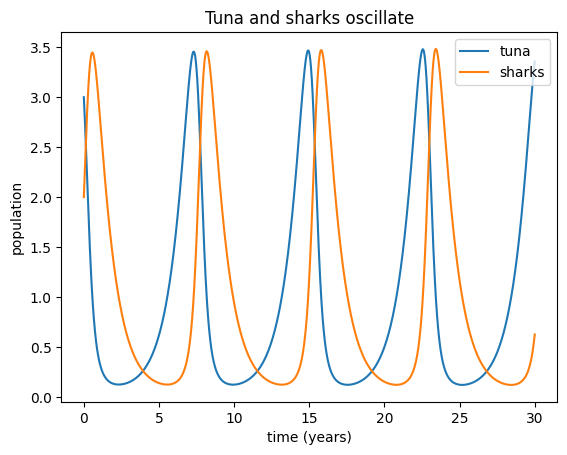

In [6]:
def simulate(S, T, dt, t_end):
    times = []
    sharks = []
    tuna = []

    for i in range(int(t_end / dt)):
        times.append(i * dt)
        sharks.append(S)
        tuna.append(T)

        dS, dT = change(S, T)
        S = S + dt * dS
        T = T + dt * dT

    return times, sharks, tuna


t, S_list, T_list = simulate(2.0, 3.0, 0.001, 30)

plt.plot(t, T_list, label='tuna')
plt.plot(t, S_list, label='sharks')
plt.xlabel('time (years)')
plt.ylabel('population')
plt.title('Tuna and sharks oscillate')
plt.legend()
plt.show()


sasdfljkasdlfjalsjdf